## 1. IMPORTS 

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error, roc_auc_score, classification_report,
    confusion_matrix, roc_curve, auc, precision_recall_curve, accuracy_score, recall_score
)

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.formula.api as smf

import shap 

import warnings
warnings.filterwarnings("ignore")

pd.options.display.float_format = '{:,.2f}'.format

pd.set_option('display.max_columns', None)  # Mostra todas as colunas

## 2. LOAD DATA

In [2]:
df = pd.read_csv("./data/acquisition_train.csv")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 43 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   ids                                               45000 non-null  str    
 1   target_default                                    41741 non-null  object 
 2   score_1                                           44438 non-null  str    
 3   score_2                                           44438 non-null  str    
 4   score_3                                           44438 non-null  float64
 5   score_4                                           45000 non-null  float64
 6   score_5                                           45000 non-null  float64
 7   score_6                                           45000 non-null  float64
 8   risk_rate                                         44438 non-null  float64
 9   last_amount_borrowed        

## DROP NA ONLY target_default

In [4]:
target = "target_default"
df2 = df.copy()
df2[target] = pd.to_numeric(df2[target], errors='coerce')
df2 = df2.dropna(subset=[target])

## 3. CLEANING

In [5]:
drop_cols = ["ids","score_1","score_2","zip","shipping_zip_code","lat_lon","email", "application_time_applied",
             "application_time_in_funnel", "user_agent","external_data_provider_first_name",
             "external_data_provider_fraud_score", "profile_tags", "profile_phone_number", 
             "shipping_state", "target_fraud", "marketing_channel", "reason", "state", "zip", 
             "job_name", "real_state", "facebook_profile","external_data_provider_email_seen_before"]

df2 = df2.drop(columns = [c for c in drop_cols if c in df2.columns])

if "reported_income" in df2.columns:
    df2 = df2[df2["reported_income"] < 1e7]

In [6]:
df2.columns

Index(['target_default', 'score_3', 'score_4', 'score_5', 'score_6',
       'risk_rate', 'last_amount_borrowed', 'last_borrowed_in_months',
       'credit_limit', 'income', 'channel', 'ok_since', 'n_bankruptcies',
       'n_defaulted_loans', 'n_accounts', 'n_issues',
       'external_data_provider_credit_checks_last_2_year',
       'external_data_provider_credit_checks_last_month',
       'external_data_provider_credit_checks_last_year', 'reported_income'],
      dtype='str')

In [7]:
df2.shape

(41480, 20)

In [8]:
df2.head()

,target_default,score_3,score_4,score_5,score_6,risk_rate,last_amount_borrowed,last_borrowed_in_months,credit_limit,income,channel,ok_since,n_bankruptcies,n_defaulted_loans,n_accounts,n_issues,external_data_provider_credit_checks_last_2_year,external_data_provider_credit_checks_last_month,external_data_provider_credit_checks_last_year,reported_income
0,0.00,350.00,101.80,0.26,108.43,0.40,"25,033.92",36.00,0.00,"65,014.12",NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,18.00,18.00,NaN,2,0.00,"57,849.00"
1,0.00,370.00,97.06,0.94,92.00,0.24,NaN,NaN,"39,726.00","100,018.91",NCqL3QBx0pscDnx3ixKwXg==,50.00,0.00,0.00,14.00,14.00,0.00,1,0.00,"4,902.00"
2,1.00,360.00,100.03,0.35,112.89,0.29,"7,207.92",36.00,NaN,"65,023.65",NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,10.00,NaN,NaN,2,NaN,"163,679.00"
3,0.00,510.00,101.60,0.99,94.90,0.32,NaN,NaN,"54,591.00","68,830.01",NCqL3QBx0pscDnx3ixKwXg==,NaN,1.00,0.00,19.00,19.00,NaN,3,NaN,"1,086.00"
4,0.00,500.00,98.47,0.53,118.13,0.18,NaN,NaN,NaN,"60,011.29",NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,11.00,NaN,0.00,2,1.00,"198,618.00"


## 4. FEATURE ENGINEERING

In [9]:
if all(c in df2.columns for c in ['last_amount_borrowed','income']):
    df2['debt_to_income'] = df2['last_amount_borrowed'] / (df2['income'] + 1)

if all(c in df2.columns for c in ['last_amount_borrowed','credit_limit']):
    df2['credit_utilization'] = df2['last_amount_borrowed'] / (df2['credit_limit'] + 1)

neg_cols = ['n_bankruptcies','n_defaulted_loans','n_issues']
if all(c in df2.columns for c in neg_cols):
    df2['total_negatives'] = df2[neg_cols].sum(axis=1)

if 'income' in df2.columns:
    df2['income_log'] = np.log1p(df2['income'])

score_cols = [c for c in df2.columns if 'score_' in c]
for col in score_cols:
    df2[col] = pd.to_numeric(df2[col], errors = "coerce")
if score_cols:
    df2['score_mean'] = df2[score_cols].mean(axis=1)

df2[score_cols].dtypes 

score_3    float64
score_4    float64
score_5    float64
score_6    float64
dtype: object

In [10]:
df2 = df2.drop(columns=["income",'score_3','score_4','score_5','score_6'])

# Dicionário de Dados

## Variável Alvo

| Variável | Tipo | Descrição |
|----------|------|-----------|
| `target_default` | Binária | Variável alvo do modelo. Indica se o cliente entrou em inadimplência (`1`) ou não (`0`). |

---

## Variáveis Numéricas

| Variável | Tipo | Descrição |
|----------|------|-----------|
| `risk_rate` | Numérica | Taxa de risco atribuída ao cliente pela instituição financeira. Quanto maior o valor, maior o risco estimado. |
| `last_amount_borrowed` | Numérica | Valor do último empréstimo contratado pelo cliente. |
| `last_borrowed_in_months` | Numérica | Quantidade de meses desde o último empréstimo realizado. |
| `credit_limit` | Numérica | Limite de crédito disponível para o cliente. |
| `income` | Numérica | Renda informada pelo cliente. |
| `ok_since` | Numérica | Tempo (em meses) desde o início do histórico positivo do cliente. Quanto maior, maior o tempo de relacionamento sem ocorrências negativas. |
| `n_bankruptcies` | Inteira | Número de registros de falência associados ao cliente. |
| `n_defaulted_loans` | Inteira | Quantidade de empréstimos anteriores que entraram em inadimplência. |
| `n_accounts` | Inteira | Número de contas financeiras vinculadas ao cliente. |
| `n_issues` | Inteira | Quantidade de ocorrências ou restrições registradas no histórico do cliente. |
| `external_data_provider_credit_checks_last_2_year` | Inteira | Número de consultas ao histórico de crédito realizadas nos últimos dois anos. |
| `external_data_provider_credit_checks_last_month` | Inteira | Número de consultas ao histórico de crédito realizadas no último mês. |
| `external_data_provider_credit_checks_last_year` | Inteira | Número de consultas ao histórico de crédito realizadas no último ano. |

---

## Variáveis Categóricas

| Variável | Tipo | Descrição |
|----------|------|-----------|
| `channel` | Categórica | Canal utilizado pelo cliente para contratação do crédito (ex.: aplicativo, agência, internet etc.). Foi transformada por One-Hot Encoding durante o pré-processamento. |

---

# Variáveis Criadas (Feature Engineering)

| Variável | Fórmula | Descrição |
|----------|----------|-----------|
| `debt_to_income` | `last_amount_borrowed / income` | Representa o comprometimento da renda pelo valor do último empréstimo. Valores maiores indicam maior exposição financeira. |
| `credit_utilization` | `last_amount_borrowed / credit_limit` | Percentual aproximado do limite de crédito utilizado pelo cliente. Quanto maior, maior o nível de utilização do crédito disponível. |
| `total_negatives` | `n_bankruptcies + n_defaulted_loans + n_issues` | Indicador agregado de eventos negativos no histórico financeiro do cliente. |
| `income_log` | `log1p(income)` | Transformação logarítmica da renda utilizada para reduzir assimetria e diminuir o impacto de valores extremos. |
| `score_mean` | Média dos scores disponíveis | Média dos diferentes scores de crédito presentes na base, utilizada para reduzir redundância entre variáveis semelhantes. |

---

# Observações

- Os valores ausentes foram tratados durante o pré-processamento.
- As variáveis categóricas foram convertidas utilizando **One-Hot Encoding**.
- As variáveis numéricas foram padronizadas antes do treinamento dos modelos.
- As variáveis criadas durante o Feature Engineering contribuíram significativamente para o desempenho do modelo Random Forest, aparecendo entre as mais importantes na análise de importância das variáveis.

In [11]:
df2.describe().T

,count,mean,std,min,25%,50%,75%,max
target_default,"41,480.00",0.16,0.37,0.00,0.00,0.00,0.00,1.00
risk_rate,"41,480.00",0.29,0.10,0.00,0.22,0.29,0.36,0.90
last_amount_borrowed,"14,035.00","13,323.05","7,918.26","1,005.18","7,210.12","12,010.95","18,028.97","35,059.60"
last_borrowed_in_months,"14,035.00",40.59,9.44,36.00,36.00,36.00,36.00,60.00
credit_limit,"28,455.00","33,878.35","36,155.72",0.00,"9,973.50","25,220.00","46,500.50","448,269.00"
ok_since,"17,167.00",35.21,21.65,0.00,17.00,32.00,50.00,141.00
n_bankruptcies,"41,346.00",0.08,0.27,0.00,0.00,0.00,0.00,5.00
n_defaulted_loans,"41,468.00",0.00,0.08,0.00,0.00,0.00,0.00,5.00
n_accounts,"41,480.00",10.64,4.59,0.00,7.00,10.00,13.00,49.00
n_issues,"30,629.00",11.02,4.60,0.00,8.00,10.00,14.00,49.00


In [12]:
df2.columns

Index(['target_default', 'risk_rate', 'last_amount_borrowed',
       'last_borrowed_in_months', 'credit_limit', 'channel', 'ok_since',
       'n_bankruptcies', 'n_defaulted_loans', 'n_accounts', 'n_issues',
       'external_data_provider_credit_checks_last_2_year',
       'external_data_provider_credit_checks_last_month',
       'external_data_provider_credit_checks_last_year', 'reported_income',
       'debt_to_income', 'credit_utilization', 'total_negatives', 'income_log',
       'score_mean'],
      dtype='str')

In [13]:
# df2['income_log'] = np.log1p(df2['income'])
# df2 = df2.drop(columns=['income'])

In [14]:
df2.describe().T

,count,mean,std,min,25%,50%,75%,max
target_default,"41,480.00",0.16,0.37,0.00,0.00,0.00,0.00,1.00
risk_rate,"41,480.00",0.29,0.10,0.00,0.22,0.29,0.36,0.90
last_amount_borrowed,"14,035.00","13,323.05","7,918.26","1,005.18","7,210.12","12,010.95","18,028.97","35,059.60"
last_borrowed_in_months,"14,035.00",40.59,9.44,36.00,36.00,36.00,36.00,60.00
credit_limit,"28,455.00","33,878.35","36,155.72",0.00,"9,973.50","25,220.00","46,500.50","448,269.00"
ok_since,"17,167.00",35.21,21.65,0.00,17.00,32.00,50.00,141.00
n_bankruptcies,"41,346.00",0.08,0.27,0.00,0.00,0.00,0.00,5.00
n_defaulted_loans,"41,468.00",0.00,0.08,0.00,0.00,0.00,0.00,5.00
n_accounts,"41,480.00",10.64,4.59,0.00,7.00,10.00,13.00,49.00
n_issues,"30,629.00",11.02,4.60,0.00,8.00,10.00,14.00,49.00


In [15]:
df2.head()

,target_default,risk_rate,last_amount_borrowed,last_borrowed_in_months,credit_limit,channel,ok_since,n_bankruptcies,n_defaulted_loans,n_accounts,n_issues,external_data_provider_credit_checks_last_2_year,external_data_provider_credit_checks_last_month,external_data_provider_credit_checks_last_year,reported_income,debt_to_income,credit_utilization,total_negatives,income_log,score_mean
0,0.00,0.40,"25,033.92",36.00,0.00,NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,18.00,18.00,NaN,2,0.00,"57,849.00",0.39,"25,033.92",18.00,11.08,140.12
1,0.00,0.24,NaN,NaN,"39,726.00",NCqL3QBx0pscDnx3ixKwXg==,50.00,0.00,0.00,14.00,14.00,0.00,1,0.00,"4,902.00",NaN,NaN,14.00,11.51,140.00
2,1.00,0.29,"7,207.92",36.00,NaN,NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,10.00,NaN,NaN,2,NaN,"163,679.00",0.11,NaN,0.00,11.08,143.32
3,0.00,0.32,NaN,NaN,"54,591.00",NCqL3QBx0pscDnx3ixKwXg==,NaN,1.00,0.00,19.00,19.00,NaN,3,NaN,"1,086.00",NaN,NaN,20.00,11.14,176.87
4,0.00,0.18,NaN,NaN,NaN,NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,11.00,NaN,0.00,2,1.00,"198,618.00",NaN,NaN,0.00,11.00,179.28


## 5. SPLIT

In [16]:
X = df2.drop(columns=[target])
y = df2[target]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3, stratify=y, random_state=42)

In [17]:
X_train

,risk_rate,last_amount_borrowed,last_borrowed_in_months,credit_limit,channel,ok_since,n_bankruptcies,n_defaulted_loans,n_accounts,n_issues,external_data_provider_credit_checks_last_2_year,external_data_provider_credit_checks_last_month,external_data_provider_credit_checks_last_year,reported_income,debt_to_income,credit_utilization,total_negatives,income_log,score_mean
39639,0.24,NaN,NaN,"237,750.00",NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,20.00,20.00,0.00,0,NaN,"96,369.00",NaN,NaN,20.00,12.30,164.35
44983,0.31,NaN,NaN,"94,531.00",NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,14.00,14.00,0.00,0,NaN,"88,964.00",NaN,NaN,14.00,11.35,139.02
9346,0.39,NaN,NaN,NaN,NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,8.00,8.00,0.00,0,NaN,"136,319.00",NaN,NaN,8.00,10.17,141.43
11887,0.19,"3,026.22",36.00,NaN,NCqL3QBx0pscDnx3ixKwXg==,22.00,0.00,0.00,11.00,11.00,NaN,0,NaN,"192,446.00",0.10,NaN,11.00,10.28,159.29
5978,0.24,NaN,NaN,NaN,NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,9.00,NaN,NaN,2,NaN,"76,809.00",NaN,NaN,0.00,11.63,57.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25225,0.26,NaN,NaN,"42,840.00",NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,15.00,15.00,0.00,3,0.00,"153,854.00",NaN,NaN,15.00,11.17,119.13
37773,0.41,"24,023.31",36.00,NaN,NCqL3QBx0pscDnx3ixKwXg==,38.00,0.00,0.00,11.00,NaN,NaN,1,NaN,"9,825.00",0.14,NaN,0.00,12.04,222.14
42151,0.36,NaN,NaN,"46,184.00",NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,15.00,15.00,NaN,2,NaN,"111,539.00",NaN,NaN,15.00,11.17,154.00
40146,0.25,NaN,NaN,"47,306.00",NCqL3QBx0pscDnx3ixKwXg==,NaN,0.00,0.00,5.00,5.00,NaN,3,NaN,"109,816.00",NaN,NaN,5.00,10.81,174.72


# MACHINE LEARNING

## 6. PIPELINE

In [18]:
num_cols = X_train.select_dtypes(include=['int64','float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

## 7. MODELOS

In [20]:
scale_pos_weight = sum(y_train == 0) / sum(y_train == 1)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(),
    'XGBoost': XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        use_label_encoder=False
    )
}

## 8. TREINO

In [21]:
pipelines = {}
results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    
    y_pred = pipe.predict_proba(X_test)[:,1]
    auc = roc_auc_score(y_test, y_pred)
    
    results.append((name, auc))
    print(f'{name}: AUC = {auc:.4f}')

Logistic Regression: AUC = 0.6253
Random Forest: AUC = 0.6293
Gradient Boosting: AUC = 0.6259
XGBoost: AUC = 0.6116


## 9. ROC

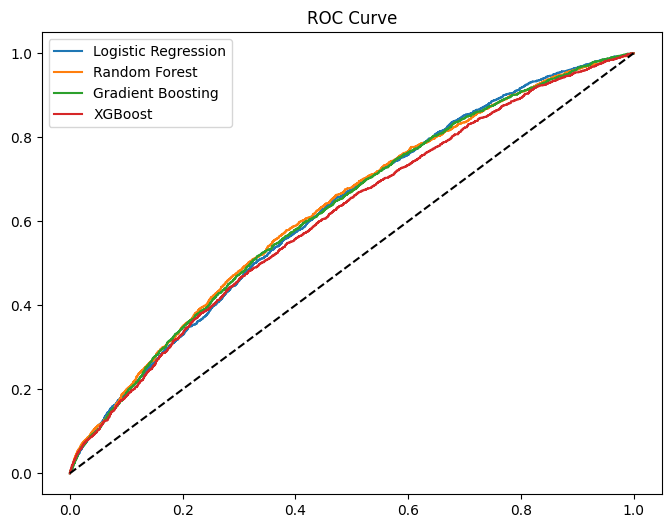

In [22]:
plt.figure(figsize=(8,6))

for name, pipe in pipelines.items():
    y_pred = pipe.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_pred)
    plt.plot(fpr, tpr, label=name)

plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title('ROC Curve')
plt.show()

## 10. KS

In [23]:
def ks_stat(y_true, y_pred):
    df_ks = pd.DataFrame({'y': y_true, 'prob': y_pred}).sort_values('prob')
    df_ks['cum_good'] = (df_ks['y'] == 0).cumsum() / sum(df_ks['y'] == 0)
    df_ks['cum_bad'] = (df_ks['y'] == 1).cumsum() / sum(df_ks['y'] == 1)
    return max(abs(df_ks['cum_good'] - df_ks['cum_bad']))

for name, pipe in pipelines.items():
    y_pred = pipe.predict_proba(X_test)[:,1]
    print(f'{name} KS:', ks_stat(y_test, y_pred))

Logistic Regression KS: 0.18396301361394368
Random Forest KS: 0.19429552478364032
Gradient Boosting KS: 0.18445584958160938
XGBoost KS: 0.16385842607951584


## 11. MELHOR MODELO

In [24]:
best_model = sorted(results, key=lambda x: x[1], reverse=True)[0]
best_pipe = pipelines[best_model[0]]
best_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

## 12. FEATURE IMPORTANCE

In [25]:
model = best_pipe.named_steps['model']

if hasattr(model, 'feature_importances_'):
    ohe = best_pipe.named_steps['preprocessor'] \
        .named_transformers_['cat']['onehot']
    
    cat_features = ohe.get_feature_names_out(cat_cols)

    all_features = list(num_cols) + list(cat_features)

    feat_imp = pd.DataFrame({
        'feature': all_features,
        'importance': model.feature_importances_
    }).sort_values(by='importance', ascending=False)

    print("\nTop Features:")
    print(feat_imp.head(10))


Top Features:
                    feature  importance
0                 risk_rate        0.14
16               income_log        0.12
13           debt_to_income        0.10
2   last_borrowed_in_months        0.10
17               score_mean        0.09
1      last_amount_borrowed        0.08
12          reported_income        0.07
3              credit_limit        0.06
14       credit_utilization        0.05
4                  ok_since        0.05


## 13. SHAP

In [26]:
# try:
#     model = best_pipe.named_steps['model']

#     X_processed = best_pipe.named_steps['preprocessor'].transform(X_train)
#     X_processed_df = pd.DataFrame(X_processed, columns=all_features)

#     # usar TreeExplainer para modelos de árvore
#     explainer = shap.TreeExplainer(model)
#     shap_values = explainer.shap_values(X_processed_df)

#     # se for classificação binária
#     if isinstance(shap_values, list):
#         shap.summary_plot(shap_values[1], X_processed_df)
#     else:
#         shap.summary_plot(shap_values, X_processed_df)

# except Exception as e:
#     print("Erro no SHAP:", e)

## 14. SCORE

In [27]:
y_pred = best_pipe.predict_proba(X_test)[:,1]

score = 1000 - (y_pred * 1000)

score_df = pd.DataFrame({
    'prob_default': y_pred,
    'score': score
})

print(score_df.head())

   prob_default  score
0          0.12 879.02
1          0.22 783.75
2          0.15 848.30
3          0.11 885.64
4          0.11 891.87


Precision: 0.2713
Recall: 0.2049

Relatório de Classificação:
              precision    recall  f1-score   support

         0.0       0.86      0.90      0.88     10458
         1.0       0.27      0.20      0.23      1986

    accuracy                           0.79     12444
   macro avg       0.56      0.55      0.55     12444
weighted avg       0.76      0.79      0.77     12444



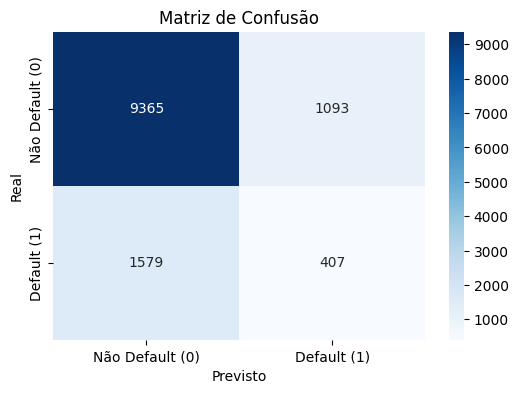

In [28]:
# ===============================
# AVALIAÇÃO DO MODELO
# ===============================

from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

# ===============================
# PREDIÇÕES
# ===============================

# Probabilidade da classe positiva (inadimplente = 1)
y_proba = best_pipe.predict_proba(X_test)[:, 1]

# Definir threshold (padrão = 0.5)
threshold = 0.2
y_pred = (y_proba >= threshold).astype(int)

# ===============================
# MÉTRICAS
# ===============================

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')

print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

# ===============================
# MATRIZ DE CONFUSÃO
# ===============================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Matriz de Confusão')
plt.xlabel('Previsto')
plt.ylabel('Real')

# Labels (ajuste se quiser)
plt.xticks([0.5, 1.5], ['Não Default (0)', 'Default (1)'])
plt.yticks([0.5, 1.5], ['Não Default (0)', 'Default (1)'])

plt.show()